# Native categorical boosting, calibration and geographic shift
Extend Adult classification and California housing regression with CatBoost and
quantile uncertainty, preserving the earlier held-out protocols.
[Results](../docs/modern_results.md) and [split rationale](../docs/03_uncertainty_and_shift.md).

In [1]:
from pathlib import Path
import json
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
root = Path.cwd()
while not (root / 'pyproject.toml').exists() and root != root.parent:
    root = root.parent
sys.path.insert(0, str(root / 'src'))
def evidence(study):
    return json.loads((root / 'results' / 'reference' / study / 'metrics.json').read_text())
plt.rcParams.update({'figure.figsize': (7, 4), 'axes.spines.top': False, 'axes.spines.right': False})

from io import BytesIO
from PIL import Image as PILImage
from IPython.display import Image as NotebookImage, display
def preview(path):
    # Compressed display preview; full-resolution scientific figures remain in assets.
    with PILImage.open(path) as picture:
        picture.thumbnail((760,760))
        buffer = BytesIO()
        picture.convert('RGB').save(buffer,format='JPEG',quality=90)
    display(NotebookImage(data=buffer.getvalue()))

In [2]:
m = evidence('modern_tabular')
pd.DataFrame(m['classification'])

,model,seed,accuracy,roc_auc,average_precision,log_loss,brier,ece,temperature,set_coverage,set_size,decision_threshold,decision_cost,selected_depth,tree_count,seconds_including_selection
0,catboost_native,0,0.872244,0.926340,0.823577,0.278959,0.088531,0.011665,0.941655,0.898839,1.058473,0.24,0.197469,8,446,45.871820
1,catboost_native,1,0.871814,0.927281,0.825264,0.276769,0.088052,0.007984,1.029502,0.896874,1.050427,0.40,0.197838,6,1165,61.333206
2,catboost_native,2,0.873165,0.927534,0.825753,0.276494,0.087834,0.007023,1.035877,0.897304,1.051901,0.28,0.193047,6,1137,76.915360


In [3]:
pd.DataFrame(m['paired'])

,task,seed,comparison,difference,ci95,repeats,unit
0,classification,0,native CatBoost minus histogram boosting NLL,-0.000568,"[-0.00268451893687918, 0.0016099906750159103]",1000,test example
1,classification,1,native CatBoost minus histogram boosting NLL,-0.003954,"[-0.006030301788299657, -0.0018391563795276732]",1000,test example
2,classification,2,native CatBoost minus histogram boosting NLL,-0.002089,"[-0.003917374005717987, -0.0003137029025771368]",1000,test example


## Post-fit error analysis
Inspect calibration, subgroup coverage and permutation sensitivity using fixed checkpoints. This analysis never chooses a model or threshold; marginal coverage does not guarantee subgroup coverage.

In [4]:
analysis = json.loads((root/'results/reference/modern_tabular/diagnostics.json').read_text())
pd.DataFrame(analysis['groups_seed0'])[['feature','group','n','roc_auc','ece','set_coverage','tpr','fpr']]

,feature,group,n,roc_auc,ece,set_coverage,tpr,fpr
0,sex,Female,5421,0.944262,0.009545,0.946135,0.761017,0.063755
1,sex,Male,10860,0.908678,0.014210,0.875230,0.871007,0.234745
2,race,Amer-Indian-Eskimo,159,0.961278,0.050525,0.943396,0.894737,0.092857
3,race,Asian-Pac-Islander,480,0.908019,0.060151,0.872917,0.849624,0.198847
4,race,Black,1561,0.947208,0.015047,0.941063,0.793296,0.070912
5,race,Other,135,0.972000,0.067532,0.903704,0.720000,0.027273
6,race,White,13946,0.922864,0.011686,0.894450,0.858166,0.182670


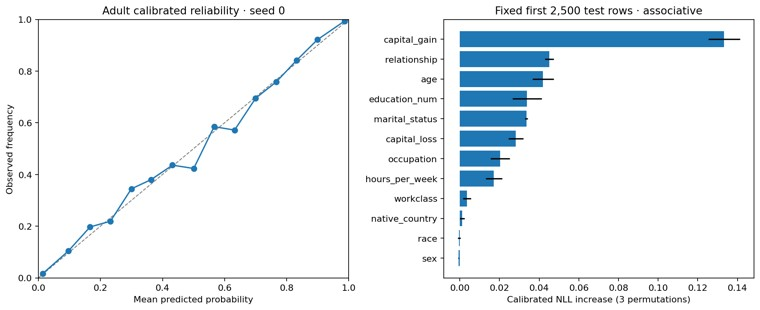

,feature,NLL increase,repeat SD
2,capital_gain,0.133255,0.007964
8,relationship,0.045117,0.002133
0,age,0.041952,0.005391
1,education_num,0.033835,0.007363
6,marital_status,0.033584,0.000727
3,capital_loss,0.028245,0.003720
7,occupation,0.020375,0.004860
4,hours_per_week,0.017185,0.004233
5,workclass,0.003569,0.002072
11,native_country,0.001146,0.001196


In [5]:
preview(root/'assets/modern_tabular_diagnostics.png')
pd.DataFrame(analysis['permutation_seed0']).sort_values('NLL increase',ascending=False)

## Keep tuning, probability calibration and coverage calibration separate
Depth and early stopping use validation labels. A separate probability partition
fits temperature. Another conformal partition chooses the cutoff. Decision costs
are an explicit illustrative choice, not a claim about income decisions in practice.

In [6]:
rows = []
for row in m['regression']:
    rows.append({k:v for k,v in row.items() if isinstance(v,(str,int,float))} |
                {'coverage':row['split_conformal']['coverage'],
                 'CQR coverage':row['cqr']['coverage']})
pd.DataFrame(rows)

,model,protocol,seed,rmse,mae,selected_depth,tree_count,seconds_including_selection,coverage,CQR coverage
0,catboost_native,random,0,0.435802,0.286963,8,1997,26.763889,0.900194,0.883236
1,catboost_native,random,1,0.444379,0.286371,8,1995,28.293495,0.894864,0.895833
2,catboost_native,random,2,0.451098,0.293288,8,2000,26.564861,0.903828,0.907946
3,catboost_native,geographic,0,0.951247,0.796323,6,2000,21.718134,0.412877,0.309000
4,catboost_native,geographic,1,0.979492,0.825480,8,1862,21.949247,0.415989,0.450215
5,catboost_native,geographic,2,0.989251,0.818717,8,2000,29.052734,0.438248,0.318095


In [7]:
from learning_lab.uncertainty import conformal_quantile
scores = np.arange(1.,10.)
q = conformal_quantile(scores,.2)
assert q == 8.
print('Finite-sample conformal order statistic:',q)
pd.DataFrame(m['selection']).head()

Finite-sample conformal order statistic: 8.0


,task,seed,candidates,protocol
0,classification,0,"[{'depth': 6, 'validation_nll': 0.281614079944...",NaN
1,classification,1,"[{'depth': 6, 'validation_nll': 0.276234402659...",NaN
2,classification,2,"[{'depth': 6, 'validation_nll': 0.259950089342...",NaN
3,regression,0,"[{'depth': 6, 'validation_rmse': 0.46366604056...",random
4,regression,1,"[{'depth': 6, 'validation_rmse': 0.44413888466...",random


## Worked answer
Can stronger boosting repair the geographic coverage collapse? Better predictive
accuracy does not restore exchangeability between calibration and shifted test data.
The results retain this failure and compare random and geographic splits explicitly.
Native categories avoid fitting a global one-hot vocabulary; this does not make the
model immune to unseen categories, missingness shift or population changes.